In [ ]:
# Mini Project

Member 1: Setup, Loading and Cleaning
Cell 1.1: Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
from io import StringIO

sns.set_theme(style="whitegrid", context="notebook")

POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3",
              "Benzene", "Toluene", "Xylene"]
BUCKET_ORDER = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

Cell 1.2: Upload and load city_day.csv

In [ ]:
from google.colab import files
uploaded = files.upload()                      # choose city_day.csv
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name, parse_dates=["Date"])
df.head()

Saving city_day.csv to city_day.csv


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


Cell 1.3: Inspect the dataset

In [ ]:
print("Shape:", df.shape)
print("Date range:", df["Date"].min().date(), "->", df["Date"].max().date())
print("Number of cities:", df["City"].nunique())
print("\nMissing values (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))
df.describe().T

Shape: (29531, 16)
Date range: 2015-01-01 -> 2020-07-01
Number of cities: 26

Missing values (%):
Xylene        61.3
PM10          37.7
NH3           35.0
Toluene       27.2
Benzene       19.0
AQI           15.9
AQI_Bucket    15.9
PM2.5         15.6
NOx           14.2
O3            13.6
SO2           13.1
NO2           12.1
NO            12.1
CO             7.0
Date           0.0
City           0.0
dtype: float64


,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118080,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


Cell 1.4: Missing-value heatmap (Chart 1)

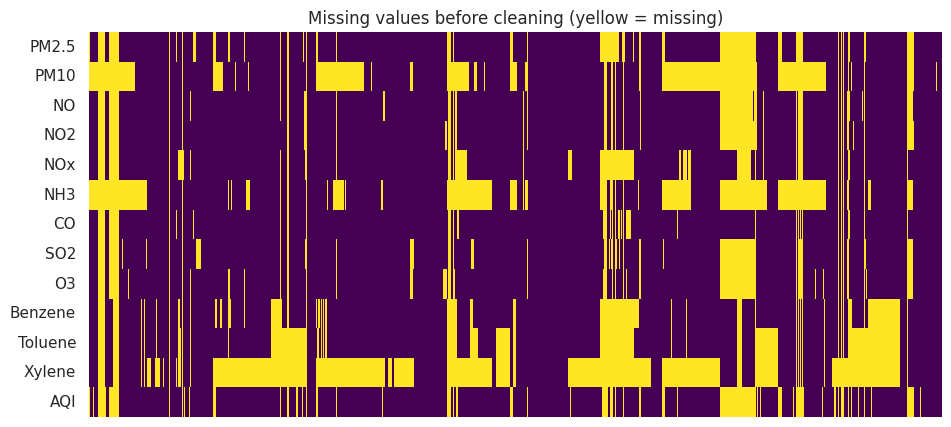

In [ ]:
df = df.sort_values(["City", "Date"]).copy()

plt.figure(figsize=(11, 5))
sns.heatmap(df[POLLUTANTS + ["AQI"]].isna().T, cbar=False, cmap="viridis", xticklabels=False)
plt.title("Missing values before cleaning (yellow = missing)")
plt.show()

Cell 1.5: Clean the data


In [ ]:
cols = POLLUTANTS + ["AQI"]

df[cols] = (df.groupby("City", group_keys=False)[cols]
              .apply(lambda g: g.interpolate(limit=7, limit_direction="both")))
df[cols] = df.groupby("City")[cols].transform(lambda s: s.fillna(s.median()))
df = df.dropna(subset=["AQI"])

bins = [-np.inf, 50, 100, 200, 300, 400, np.inf]
df["AQI_Bucket"] = pd.cut(df["AQI"], bins=bins, labels=BUCKET_ORDER)

print("Rows after cleaning:", len(df))
print("Remaining missing values:", df[cols].isna().sum().sum())

Rows after cleaning: 29531
Remaining missing values: 25138


Cell 1.6: Feature engineering

In [ ]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Season"] = df["Month"].map(
    {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer",
     5: "Summer", 6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
     10: "Post-monsoon", 11: "Post-monsoon"})
df[["City", "Date", "AQI", "AQI_Bucket", "Year", "Month", "Season"]].head()

,City,Date,AQI,AQI_Bucket,Year,Month,Season
0,Ahmedabad,2015-01-01,371.0,Very Poor,2015,1,Winter
1,Ahmedabad,2015-01-02,371.0,Very Poor,2015,1,Winter
2,Ahmedabad,2015-01-03,371.0,Very Poor,2015,1,Winter
3,Ahmedabad,2015-01-04,371.0,Very Poor,2015,1,Winter
4,Ahmedabad,2015-01-05,371.0,Very Poor,2015,1,Winter


Member 2: City and Time Analysis
Cell 2.1: Average AQI by city (Chart 2)

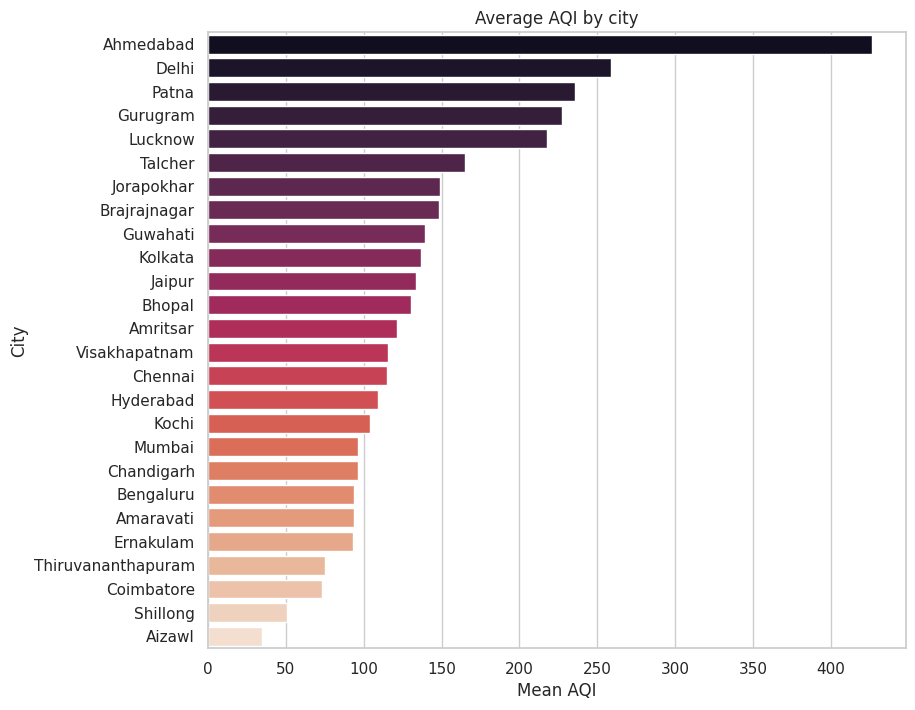

Most polluted: Ahmedabad 426.7
Cleanest     : Aizawl 34.8


In [ ]:
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 8))
sns.barplot(x=city_aqi.values, y=city_aqi.index, hue=city_aqi.index,
            palette="rocket", legend=False)
plt.xlabel("Mean AQI")
plt.title("Average AQI by city")
plt.show()

print("Most polluted:", city_aqi.index[0], round(city_aqi.iloc[0], 1))
print("Cleanest     :", city_aqi.index[-1], round(city_aqi.iloc[-1], 1))

Cell 2.2: Yearly trend of the top 5 polluted cities (Chart 3)

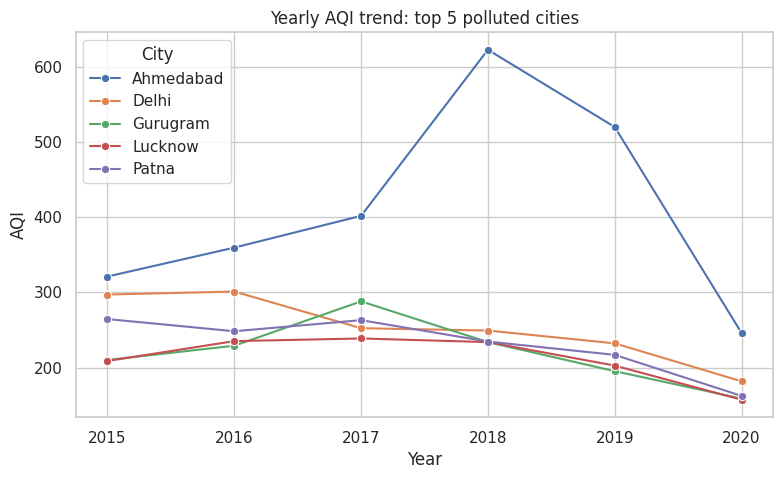

In [ ]:
top5 = city_aqi.head(5).index
yearly = (df[df["City"].isin(top5)]
          .groupby(["Year", "City"])["AQI"].mean().reset_index())

plt.figure(figsize=(9, 5))
sns.lineplot(data=yearly, x="Year", y="AQI", hue="City", marker="o")
plt.title("Yearly AQI trend: top 5 polluted cities")
plt.show()

Cell 2.3: Monthly seasonality heatmap (Chart 4)

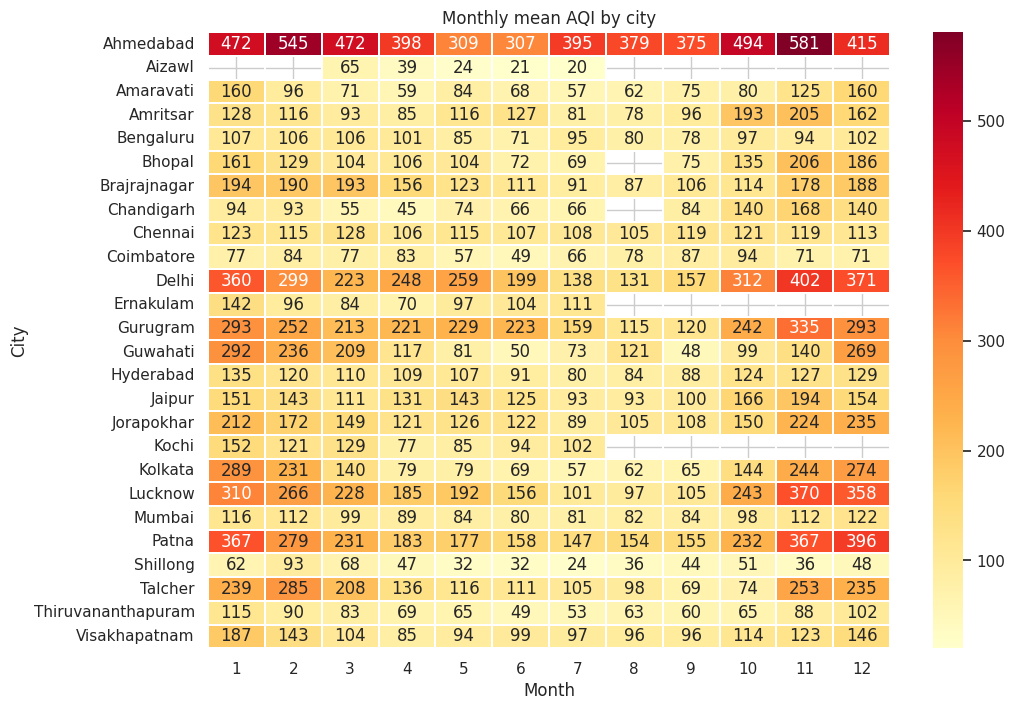

In [ ]:
pivot = df.pivot_table(index="City", columns="Month", values="AQI", aggfunc="mean")

plt.figure(figsize=(11, 8))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=.3)
plt.title("Monthly mean AQI by city")
plt.show()

Cell 2.4: AQI category distribution (Chart 5)

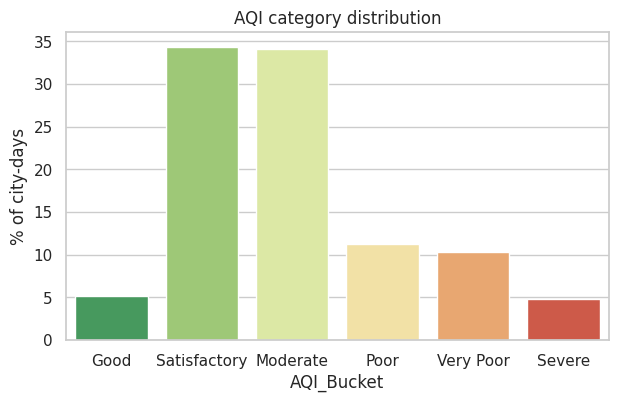

AQI_Bucket
Good             5.2
Satisfactory    34.4
Moderate        34.1
Poor            11.3
Very Poor       10.3
Severe           4.8
Name: proportion, dtype: float64


In [ ]:
bucket = df["AQI_Bucket"].value_counts(normalize=True).reindex(BUCKET_ORDER) * 100

plt.figure(figsize=(7, 4))
sns.barplot(x=bucket.index, y=bucket.values, hue=bucket.index,
            palette="RdYlGn_r", legend=False)
plt.ylabel("% of city-days")
plt.title("AQI category distribution")
plt.show()
print(bucket.round(1))

Member 3: Seasons, Pollutants and COVID Impact
Cell 3.1: AQI by season (Chart 6)

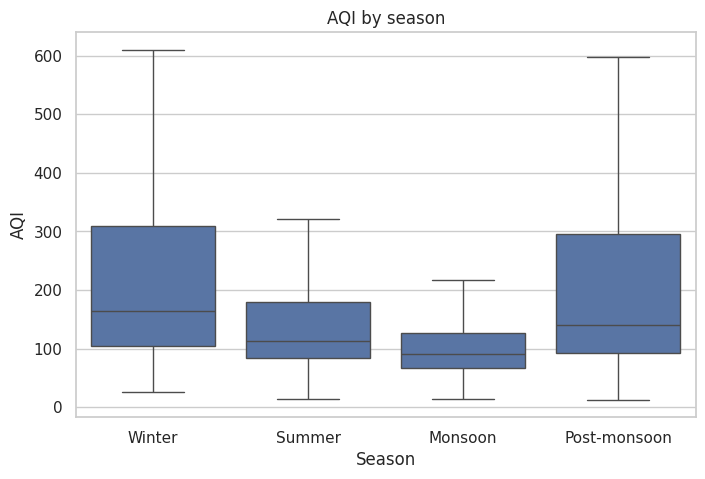

Season
Winter          214.4
Post-monsoon    206.1
Summer          151.1
Monsoon         121.3
Name: AQI, dtype: float64


In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Season", y="AQI",
            order=["Winter", "Summer", "Monsoon", "Post-monsoon"], showfliers=False)
plt.title("AQI by season")
plt.show()

print(df.groupby("Season")["AQI"].mean().round(1).sort_values(ascending=False))

Cell 3.2: Pollutant correlation matrix (Chart 7)

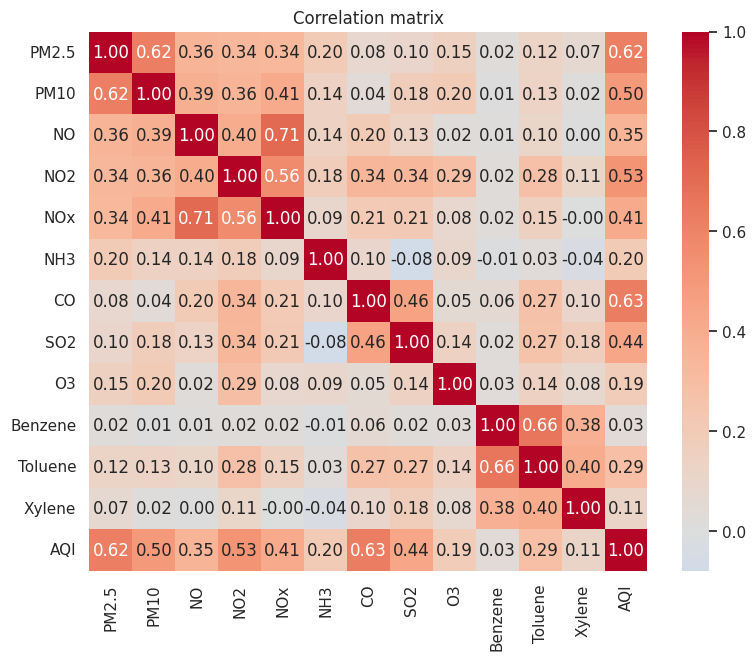

CO         0.63
PM2.5      0.62
NO2        0.53
PM10       0.50
SO2        0.44
NOx        0.41
NO         0.35
Toluene    0.29
NH3        0.20
O3         0.19
Xylene     0.11
Benzene    0.03
Name: AQI, dtype: float64


In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[POLLUTANTS + ["AQI"]].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f")
plt.title("Correlation matrix")
plt.show()

print(df[POLLUTANTS + ["AQI"]].corr()["AQI"].drop("AQI").sort_values(ascending=False).round(2))

Cell 3.3: PM2.5 vs AQI (Chart 8)

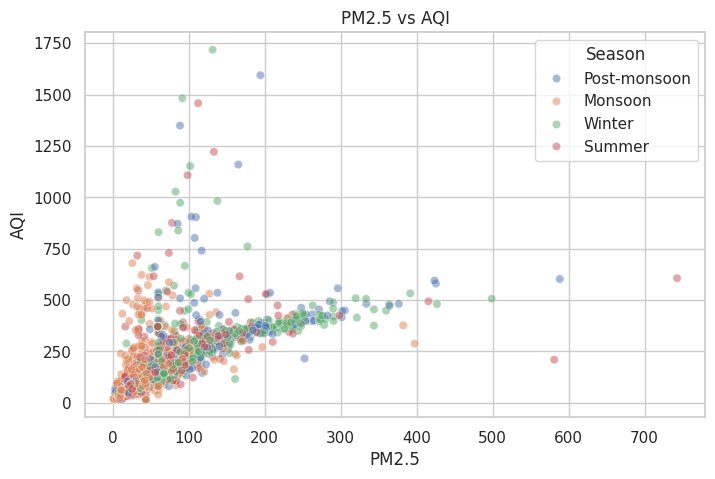

In [ ]:
sample = df.sample(3000, random_state=1)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="PM2.5", y="AQI", hue="Season", alpha=0.5)
plt.title("PM2.5 vs AQI")
plt.show()

Cell 3.4: COVID lockdown impact, 2020 vs 2019 (Chart 9)

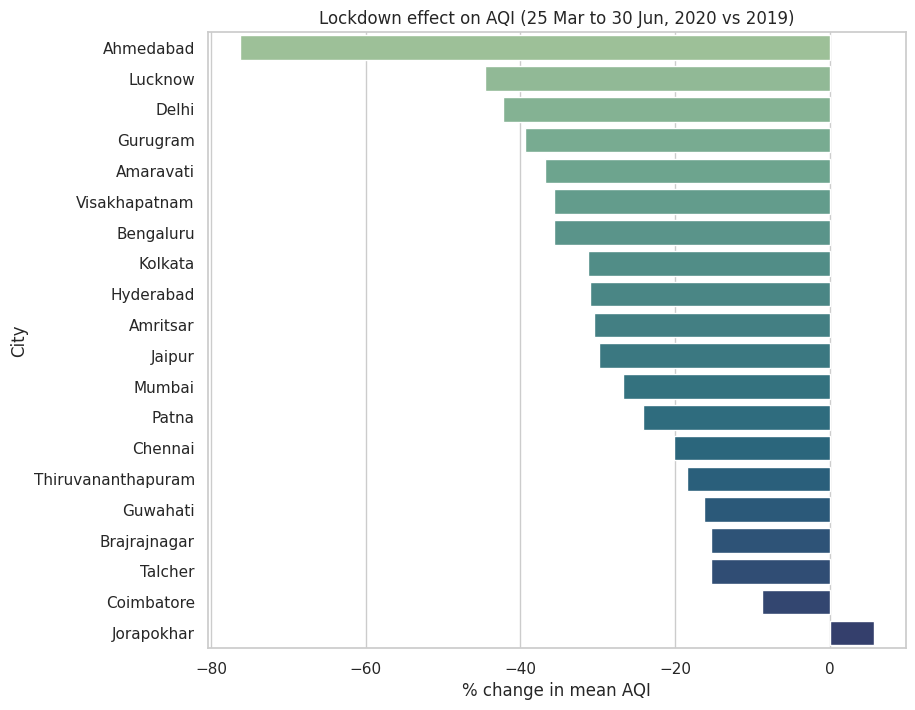

,2019,2020 (lockdown),change_%
City,,,
Ahmedabad,504.469388,119.785714,-76.3
Lucknow,193.295918,107.163265,-44.6
Delhi,217.030612,125.520408,-42.2
Gurugram,208.387755,126.204082,-39.4
Amaravati,82.510204,52.112245,-36.8
Visakhapatnam,105.994898,68.142857,-35.7
Bengaluru,102.244898,65.846939,-35.6
Kolkata,87.040816,59.877551,-31.2
Hyderabad,93.102041,64.193878,-31.0


In [ ]:
def window(year):
    return df[(df["Date"] >= f"{year}-03-25") & (df["Date"] <= f"{year}-06-30")]

compare = pd.DataFrame({
    "2019": window(2019).groupby("City")["AQI"].mean(),
    "2020 (lockdown)": window(2020).groupby("City")["AQI"].mean()
}).dropna()

compare["change_%"] = ((compare["2020 (lockdown)"] - compare["2019"]) / compare["2019"] * 100).round(1)
compare = compare.sort_values("change_%")

plt.figure(figsize=(9, 8))
sns.barplot(x=compare["change_%"], y=compare.index, hue=compare.index,
            palette="crest", legend=False)
plt.xlabel("% change in mean AQI")
plt.title("Lockdown effect on AQI (25 Mar to 30 Jun, 2020 vs 2019)")
plt.show()

compare

Member 4: NumPy Trend, Web Scraping and Conclusion
Cell 4.1: National AQI trend with NumPy (Chart 10)

National AQI trend: -13.3 AQI points per year


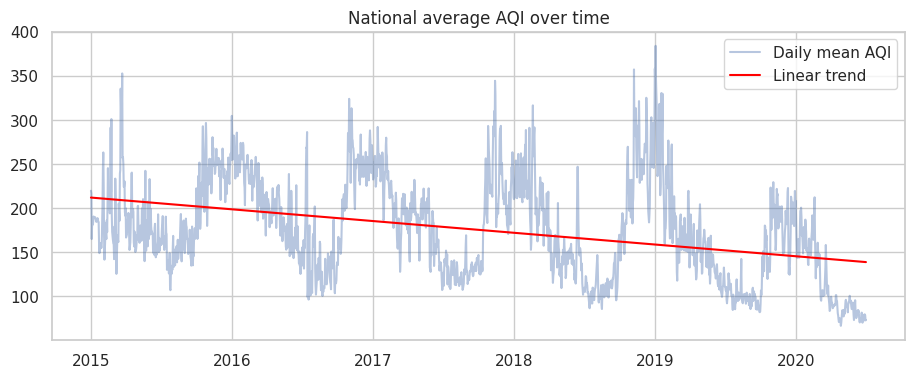

In [ ]:
national = df.groupby("Date")["AQI"].mean()
x = (national.index - national.index[0]).days.values / 365.25

slope, intercept = np.polyfit(x, national.values, 1)
trend_line = slope * x + intercept
print(f"National AQI trend: {slope:+.1f} AQI points per year")

plt.figure(figsize=(11, 4))
plt.plot(national.index, national.values, alpha=0.4, label="Daily mean AQI")
plt.plot(national.index, trend_line, color="red", label="Linear trend")
plt.title("National average AQI over time")
plt.legend()
plt.show()

Cell 4.2: Scrape city population from Wikipedia

In [ ]:
url = "https://en.wikipedia.org/wiki/List_of_cities_in_India_by_population"
headers = {"User-Agent": "Mozilla/5.0 (educational mini project)"}

resp = requests.get(url, headers=headers, timeout=20)
resp.raise_for_status()

tables = pd.read_html(StringIO(resp.text))
print("Tables found on the page:", len(tables))

pop = None
for t in tables:
    # flatten column names (some tables have two header rows)
    t.columns = [" ".join(map(str, c)) if isinstance(c, tuple) else str(c) for c in t.columns]
    cols = [c.lower() for c in t.columns]

    city_cols = [t.columns[i] for i, c in enumerate(cols) if "city" in c or "name" in c]
    pop_cols  = [t.columns[i] for i, c in enumerate(cols) if "population" in c]

    if city_cols and pop_cols:
        pop = t[[city_cols[0], pop_cols[0]]].copy()
        pop.columns = ["City", "Population"]
        break

if pop is None:
    print("No suitable table found. Use the backup table in the next cell.")
else:
    pop["City"] = pop["City"].astype(str).str.replace(r"\[.*?\]", "", regex=True).str.strip()
    pop["Population"] = pd.to_numeric(
        pop["Population"].astype(str).str.replace(r"\[.*?\]|,", "", regex=True),
        errors="coerce")
    pop = pop.dropna()
    print("Cities scraped:", len(pop))

Tables found on the page: 4
No suitable table found. Use the backup table in the next cell.


Cell 4.3: Merge with AQI and plot (Chart 11)

In [ ]:
resp = requests.get("https://en.wikipedia.org/wiki/List_of_cities_in_India_by_population",
                    headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
print(resp.status_code)
tables = pd.read_html(StringIO(resp.text))
print("Tables:", len(tables))
for i, t in enumerate(tables[:6]):
    print(i, list(t.columns))

200
Tables: 4
0 [('Name', 'Name'), ('State or Union territory', 'State or Union territory'), ('Census', '2011 Census'), ('Census', '2001 Census'), ('Census', 'Change'), ('Location', 'Location')]
1 ['vtePopulation of cities in India', 'vtePopulation of cities in India.1']
2 ['vteGeography of India', 'vteGeography of India.1']
3 [0, 1]


Cell 4.4: Final conclusions and save results

In [ ]:
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

print("========== KEY FINDINGS ==========")
print("1. Most polluted city :", city_aqi.index[0], round(city_aqi.iloc[0], 1))
print("2. Cleanest city      :", city_aqi.index[-1], round(city_aqi.iloc[-1], 1))
print("3. Worst season       :", df.groupby("Season")["AQI"].mean().idxmax())
print(f"4. National AQI trend : {slope:+.1f} points/year")
print("5. Biggest lockdown drop:", compare.index[0], compare['change_%'].iloc[0], "%")

df.to_csv("city_day_clean.csv", index=False)
files.download("city_day_clean.csv")

========== KEY FINDINGS ==========
1. Most polluted city : Ahmedabad 426.7
2. Cleanest city      : Aizawl 34.8
3. Worst season       : Winter
4. National AQI trend : -13.3 points/year
5. Biggest lockdown drop: Ahmedabad -76.3 %


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>